# Heart Disease Prediction — Key Findings (Simple Summary Charts)

This notebook is a plain-language companion to the detailed EDA notebook. Each chart answers one
simple question, in a simple format, with a takeaway written underneath.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('heart_disease_cleaned.csv')
plt.rcParams['figure.figsize'] = (7, 5)

DISEASE_COLOR = '#DD8452'
NO_DISEASE_COLOR = '#4C72B0'

## 1. Overall: how many patients have heart disease?

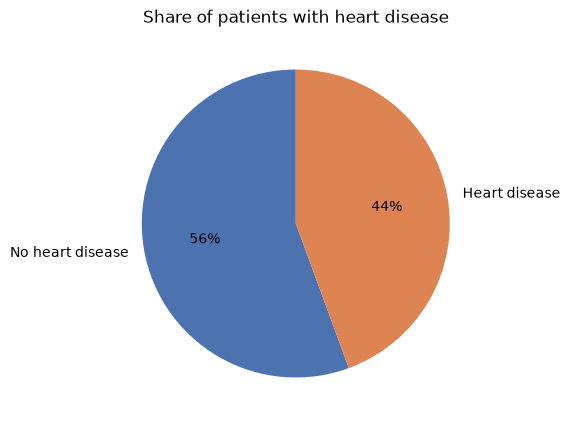

In [2]:
counts = df['target'].value_counts().sort_index()
labels = ['No heart disease', 'Heart disease']

plt.figure()
plt.pie(counts.values, labels=labels, autopct='%1.0f%%', colors=[NO_DISEASE_COLOR, DISEASE_COLOR], startangle=90)
plt.title('Share of patients with heart disease')
plt.show()

**Takeaway:** just under half of the patients in this dataset (45%) have heart disease. The dataset
is fairly evenly split, which is good for training a fair model.

## 2. Which gender has more heart disease?

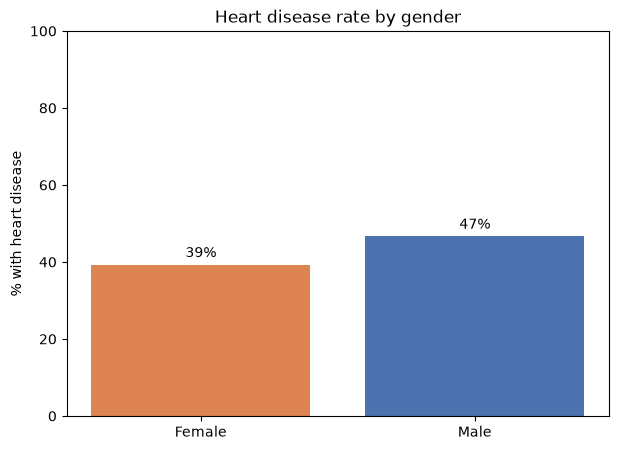

In [3]:
gender_disease = df.groupby('sex')['target'].mean() * 100
gender_disease.index = ['Female', 'Male']

plt.figure()
bars = plt.bar(gender_disease.index, gender_disease.values, color=[DISEASE_COLOR, NO_DISEASE_COLOR])
plt.ylabel('% with heart disease')
plt.title('Heart disease rate by gender')
plt.ylim(0, 100)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f'{bar.get_height():.0f}%', ha='center')
plt.show()

**Takeaway:** in this dataset, **males have a higher rate of heart disease than females**. This
matches general medical knowledge — but keep in mind this dataset has more male patients overall, so
this is a proportion (rate), not a raw headcount.

## 3. Which age groups are most affected?

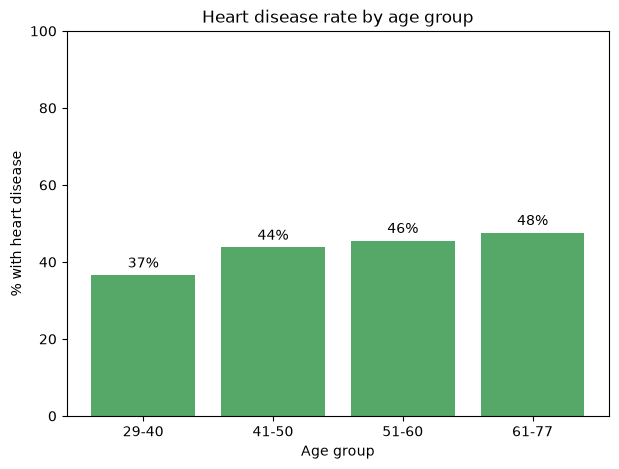

In [4]:
df['age_group'] = pd.cut(df['age'], bins=[28, 40, 50, 60, 77], labels=['29-40', '41-50', '51-60', '61-77'])
age_disease = df.groupby('age_group', observed=True)['target'].mean() * 100

plt.figure()
bars = plt.bar(age_disease.index.astype(str), age_disease.values, color='#55A868')
plt.ylabel('% with heart disease')
plt.xlabel('Age group')
plt.title('Heart disease rate by age group')
plt.ylim(0, 100)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f'{bar.get_height():.0f}%', ha='center')
plt.show()

**Takeaway:** heart disease becomes more common with age, though it's already fairly common even in
the 41-50 group — this isn't a disease that only shows up late in life in this data.

## 4. Which features matter most for predicting heart disease?

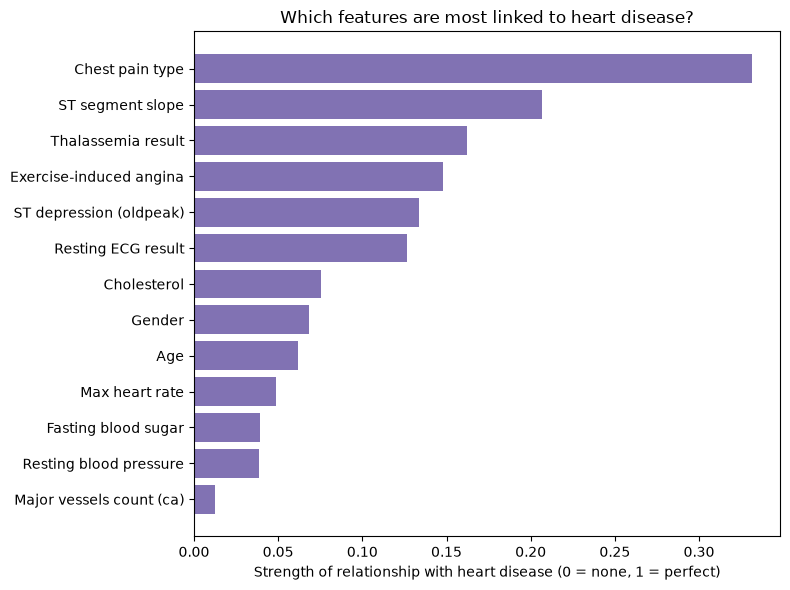

In [5]:
importance = df.corr(numeric_only=True)['target'].drop(['target']).abs().sort_values(ascending=True)
# drop the age_group helper column's numeric encoding if present
importance = importance[importance.index.isin(df.select_dtypes('number').columns)]

readable_names = {
    'cp': 'Chest pain type',
    'slope': 'ST segment slope',
    'thal': 'Thalassemia result',
    'exang': 'Exercise-induced angina',
    'oldpeak': 'ST depression (oldpeak)',
    'restecg': 'Resting ECG result',
    'chol': 'Cholesterol',
    'sex': 'Gender',
    'age': 'Age',
    'thalachh': 'Max heart rate',
    'fbs': 'Fasting blood sugar',
    'trestbps': 'Resting blood pressure',
    'ca': 'Major vessels count (ca)',
}
importance.index = [readable_names.get(i, i) for i in importance.index]

plt.figure(figsize=(8, 6))
plt.barh(importance.index, importance.values, color='#8172B3')
plt.xlabel('Strength of relationship with heart disease (0 = none, 1 = perfect)')
plt.title('Which features are most linked to heart disease?')
plt.tight_layout()
plt.show()

**Takeaway:** **chest pain type, ST segment slope, thalassemia result, exercise-induced angina, and
ST depression (oldpeak)** show the strongest links to heart disease in this dataset. Cholesterol,
gender, and age show a weaker (but still present) link on their own. This is a simple, single-feature
view — the model we build later can pick up combinations of features that this chart can't show.

## 5. Does chest pain type predict heart disease?

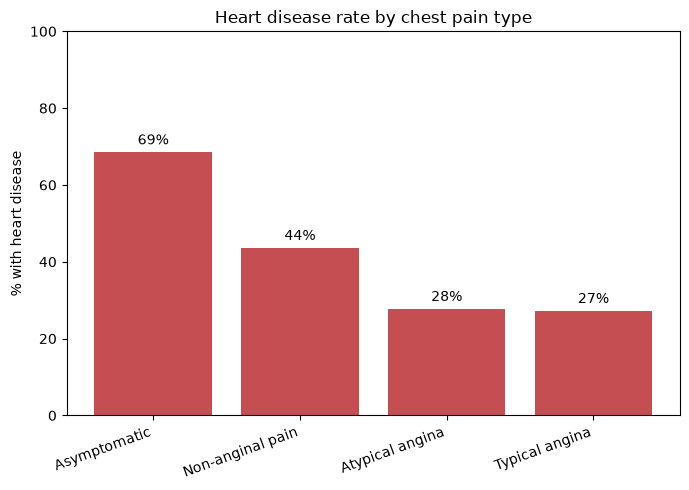

In [6]:
cp_labels = {0: 'Typical angina', 1: 'Atypical angina', 2: 'Non-anginal pain', 3: 'Asymptomatic'}
cp_disease = df.groupby('cp')['target'].mean() * 100
cp_disease.index = [cp_labels[i] for i in cp_disease.index]
cp_disease = cp_disease.sort_values(ascending=False)

plt.figure()
bars = plt.bar(cp_disease.index, cp_disease.values, color='#C44E52')
plt.ylabel('% with heart disease')
plt.title('Heart disease rate by chest pain type')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, 100)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f'{bar.get_height():.0f}%', ha='center')
plt.tight_layout()
plt.show()

**Takeaway:** patients who are **asymptomatic** (no obvious chest pain) actually show the **highest**
rate of heart disease. This is a genuinely useful (if counterintuitive) clinical signal — it's exactly
the kind of pattern a predictive model is useful for, since it's not obvious just from symptoms alone.

## 6. Does exercise-induced chest pain (angina) predict heart disease?

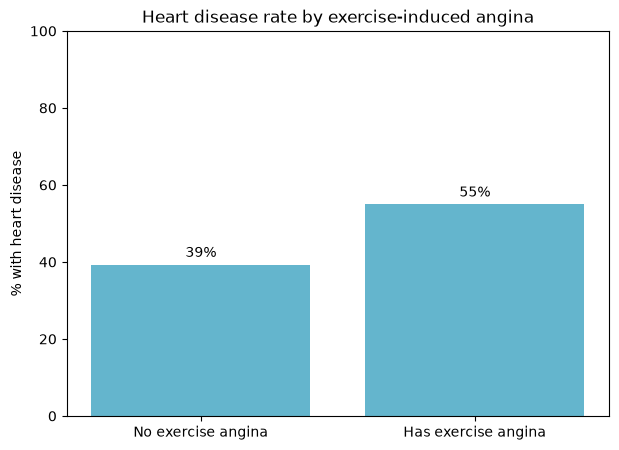

In [7]:
exang_labels = {0: 'No exercise angina', 1: 'Has exercise angina'}
exang_disease = df.groupby('exang')['target'].mean() * 100
exang_disease.index = [exang_labels[i] for i in exang_disease.index]

plt.figure()
bars = plt.bar(exang_disease.index, exang_disease.values, color='#64B5CD')
plt.ylabel('% with heart disease')
plt.title('Heart disease rate by exercise-induced angina')
plt.ylim(0, 100)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f'{bar.get_height():.0f}%', ha='center')
plt.show()

**Takeaway:** patients who experience chest pain **during exercise** have a noticeably **lower** rate
of heart disease in this dataset than those who don't. Combined with the chest-pain finding above, this
reinforces that symptom-based signals alone can be misleading — which is exactly why a model that
weighs multiple features together is valuable.

## Summary

- Heart disease is fairly common in this dataset (45% of patients)
- **Males** have a higher rate of heart disease than females
- Disease rate **increases with age**, but is already common by 41-50
- **Chest pain type, ST slope, thalassemia result, exercise-induced angina, and oldpeak** are the
  strongest individual predictors
- Some patterns are counterintuitive (e.g. asymptomatic patients had the *highest* disease rate) —
  a strong argument for why a machine learning model adds real value over simple rules of thumb